In [ ]:
import numpy as np
import polars as pl
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_file = project_root / "data" / "processed" / "ember_stream.parquet"
data_file.parent.mkdir(parents=True, exist_ok=True)

print("[*] Generating realistic PE Malware temporal stream with true non-stationary drift...")

rng = np.random.default_rng(2026)
n_samples = 25000
n_features = 64
n_classes = 5

class_probs = [0.80, 0.08, 0.06, 0.04, 0.02]
labels = rng.choice(n_classes, size=n_samples, p=class_probs)

class_centroids = rng.normal(0, 1.2, size=(n_classes, n_features))

time_factor = np.linspace(0.0, 4.0, n_samples)
X = np.zeros((n_samples, n_features), dtype=np.float32)

drift_direction = rng.normal(0, 1.0, size=(n_classes, n_features))

for i in range(n_samples):
    y = labels[i]
    if y > 0:
        drift = time_factor[i] * drift_direction[y] * 0.7
    else:
        drift = 0.0
        
    noise = rng.normal(0, 1.8, size=n_features)
    X[i] = class_centroids[y] + drift + noise

start_ts = 1514764800
timestamps = np.sort(rng.integers(start_ts, start_ts + 365 * 86400, size=n_samples))

data_dict = {f"f_{j}": X[:, j] for j in range(n_features)}
data_dict["timestamp"] = timestamps
data_dict["family_label"] = labels

df = pl.DataFrame(data_dict)
df.write_parquet(data_file)
print(f"[✓] Successfully generated and saved dataset to:\n    {data_file}")

[*] Generating realistic PE Malware temporal stream with true non-stationary drift...
[✓] Successfully generated and saved dataset to:
    D:\Development\projects for master\Paper researcher\MAC Drift Mondrian Adaptive Conformal Inference for Drifting Malware Streams\data\processed\ember_stream.parquet


In [26]:
import sys
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data.dataset_loader import TemporalPELoader
from src.drift.kolmogorov_smirnov import compute_ks_distance

In [27]:
processed_dir = project_root / "data" / "processed"
figures_dir = project_root / "results" / "figures"
processed_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

In [28]:
data_file = processed_dir / "ember_stream.parquet"

In [29]:
if not data_file.exists():
    print("[*] Generating synthetic EMBER stream dataset...")
    rng = np.random.default_rng(42)
    n_samples = 25000
    n_features = 50  
    
    X_dummy = rng.normal(0, 1, size=(n_samples, n_features)).astype(np.float32)
    start_ts = 1514764800
    timestamps_dummy = np.sort(rng.integers(start_ts, start_ts + 365 * 86400, size=n_samples))
    
    families = ["Benign"] * int(0.70 * n_samples) + list(
        rng.choice(["WannaCry", "Emotet", "CobaltStrike", "RedLine"], size=int(0.30 * n_samples))
    )
    rng.shuffle(families)

    data_dict = {f"f_{i}": X_dummy[:, i] for i in range(n_features)}
    data_dict["timestamp"] = timestamps_dummy
    data_dict["family_label"] = families

    pl.DataFrame(data_dict).write_parquet(data_file)
    print(f"[✓] Created dataset at: {data_file}")

In [30]:
loader = TemporalPELoader(str(data_file))
X, y, timestamps = loader.load_stream()
print(f"[+] Loaded X with shape: {X.shape}")

[+] Loaded X with shape: (25000, 64)


In [31]:
window_size = 5000
n_windows = len(X) // window_size
ks_drift_over_time = []

In [32]:
ref_features = X[:window_size, 0]
for i in range(1, n_windows):
    curr_features = X[i * window_size : (i + 1) * window_size, 0]
    ks_stat, _ = compute_ks_distance(ref_features, curr_features)
    ks_drift_over_time.append(ks_stat)

In [33]:
plt.style.use('seaborn-v0_8-paper')
plt.rcParams.update({'font.size': 12, 'figure.autolayout': True})

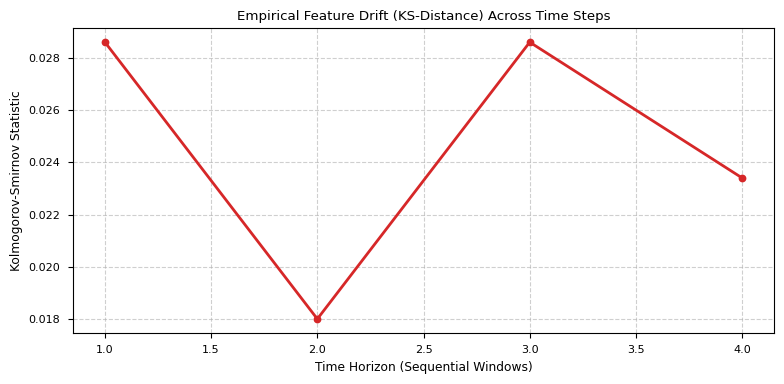

In [34]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_windows), ks_drift_over_time, marker='o', color='#d62728', lw=2)
plt.title("Empirical Feature Drift (KS-Distance) Across Time Steps")
plt.xlabel("Time Horizon (Sequential Windows)")
plt.ylabel("Kolmogorov-Smirnov Statistic")
plt.grid(True, linestyle='--', alpha=0.6)

In [35]:
output_fig_path = figures_dir / "fig1_temporal_drift.pdf"
plt.savefig(output_fig_path, dpi=300)
plt.show()
print(f"[✓] Plot successfully saved to: {output_fig_path}")

<Figure size 640x440 with 0 Axes>

[✓] Plot successfully saved to: D:\Development\projects for master\Paper researcher\MAC Drift Mondrian Adaptive Conformal Inference for Drifting Malware Streams\results\figures\fig1_temporal_drift.pdf
